# WP12 — Gemma1B v2 bellek politikası
Gerçek GGUF metadata ve teorik KV hesabı. Eski v1 eşikleri/kararları değişmez. Bu notebook API, model yükleme veya indirme yapmaz.

In [1]:
from pathlib import Path
import json,pandas as pd,matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd();Q=ROOT/'reports/qa/WP12/gemma1b_memory_v2'
m=json.loads((Q/'GGUF_metadata.json').read_text(encoding='utf-8'));b=json.loads((Q/'memory_budget.json').read_text(encoding='utf-8'));h=json.loads((Q/'hardware_snapshot.json').read_text(encoding='utf-8'))
display(pd.DataFrame([m['metadata']]).T)
display(pd.DataFrame([{'Context':c,'KV FP16 MiB':26*c*512*2/2**20,'KV FP32 MiB':26*c*512*4/2**20} for c in [512,1024,2048]]))

,0
general.architecture,gemma3
general.type,model
general.sampling.top_k,64
general.sampling.top_p,0.95
general.name,Google Gemma 3 1b It
general.finetune,it
general.basename,google-gemma-3
general.size_label,1B
general.license,gemma
general.base_model.count,1


,Context,KV FP16 MiB,KV FP32 MiB
0,512,13.0,26.0
1,1024,26.0,52.0
2,2048,52.0,104.0


**Yorum:**Tüm26 katmanda tam context hesaplandı;512 sliding-window indirimi uygulanmadı. KV sayıları toplam runtime belleği değildir. Tensor verisi yüklenmeden yalnız6,51MB metadata aralığı geçildi.

,0
weights_bytes,806058400
KV_FP16_bytes,54525952
KV_FP32_bytes,109051904
KV_assumption,"all26 layers/full2048 context, no sliding-wind..."
host_runtime_budget_bytes,536870912
host_staging_margin_bytes,268435456
host_reserve_bytes,805306368
GPU_runtime_budget_bytes,536870912
GPU_reserve_bytes,536870912
host_budget_total_bytes,2525723040


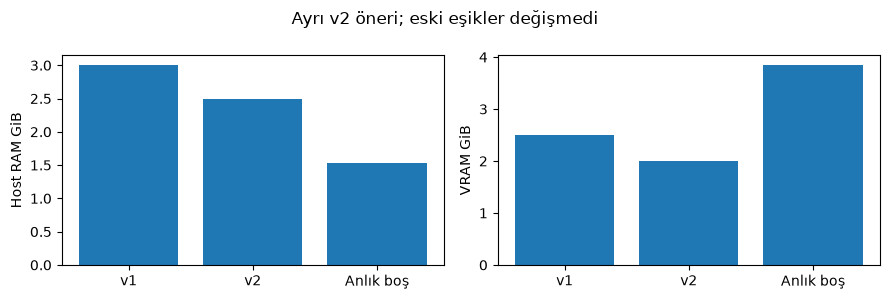

In [2]:
display(pd.DataFrame([b]).T)
fig,axs=plt.subplots(1,2,figsize=(9,3));axs[0].bar(['v1','v2','Anlık boş'],[3,2.5,h['RAM']['available']/2**30]);axs[0].set_ylabel('Host RAM GiB');axs[1].bar(['v1','v2','Anlık boş'],[2.5,2,h['GPU']['free_MiB']/1024]);axs[1].set_ylabel('VRAM GiB');fig.suptitle('Ayrı v2 öneri; eski eşikler değişmedi');fig.tight_layout();F=ROOT/'reports/figures/WP12/gemma1b_memory_v2';F.mkdir(parents=True,exist_ok=True);fig.savefig(F/'policy_comparison.png',dpi=150);plt.show()

**Yorum:**Runtime payları ölçülmemiş bütçelerdir.2,5GiB RAM/2GiB VRAM v2 kapısı;5 örnek/commit şartıyla yalnız tek teknik test için önerilir.1GiB uyarısındaki HTTP iptali sunucunun durduğunu garanti etmez. Güncel RAM yeni kapıyı da karşılamıyor; yükleme yok.

In [3]:
display(pd.DataFrame([json.loads((Q/'decision.json').read_text(encoding='utf-8'))]).T)
for name in ['test_wp12_gemma_memory_v2.py.log','test_wp12_gemma_v2_smoke_review.py.log','test_wp12_llm_preflight.py.log','test_wp12_llm_contract.py.log']:
 print(name);print((Q/name).read_text(encoding='utf-8'))
print((Q/'PowerShell_parse_check.txt').read_text(encoding='utf-8'))

test_wp12_gemma_memory_v2.py.log
test_KV_formula (test_wp12_gemma_memory_v2.MemoryTests.test_KV_formula) ... ok
test_budget_below_rounded_gates (test_wp12_gemma_memory_v2.MemoryTests.test_budget_below_rounded_gates) ... ok
test_context_linear_upper_envelope (test_wp12_gemma_memory_v2.MemoryTests.test_context_linear_upper_envelope) ... ok
test_invalid_magic_rejected (test_wp12_gemma_memory_v2.MemoryTests.test_invalid_magic_rejected) ... ok
test_real_metadata_only (test_wp12_gemma_memory_v2.MemoryTests.test_real_metadata_only) ... ok
test_truncated_header_rejected (test_wp12_gemma_memory_v2.MemoryTests.test_truncated_header_rejected) ... ok
test_unknown_or_nonfinite_fails_closed (test_wp12_gemma_memory_v2.MemoryTests.test_unknown_or_nonfinite_fails_closed) ... ok
test_v2_boundaries_and_commit (test_wp12_gemma_memory_v2.MemoryTests.test_v2_boundaries_and_commit) ... ok

----------------------------------------------------------------------
Ran 8 tests in 5.558s

OK

test_wp12_gemma_v2_smo

,0
status,WAIT_USER_HOST_V2_GATES; NO_MODEL_LOAD
current_v2_admission,False
current_free_host_GiB,1.535446
current_free_GPU_MiB,3935
memory_policy_version,WP12-gemma1b-memory-v2
sufficient_evidence_to_load_now,False
runtime_peak_RAM_VRAM,NOT_MEASURED
actual_smoke_result,None
Codex_inference_calls,0
API_calls,0


**Yorum:**50 offline test, gerçek Gemma runtime başarısı değildir. Başlangıç ve kararlılık koşulları geçmeden yükleme yapılmaz. Kullanıcı kendi PowerShell'inde tek test kaydı üretir;19×3 ve WP13 başlamadı.